# Bước 1 – Huấn luyện mô hình Embedded ML (TV6)

Hệ thống Edge-AIoT giám sát sức khỏe đất – Biochar. Notebook này huấn luyện hai mô hình sẽ chạy tại Edge Gateway:

| Mô hình | `model_code` | Đầu vào | Đầu ra |
|---|---|---|---|
| **A. Phân loại sức khỏe đất** | `SOIL-HEALTH-CLS` | 1 bản tin cảm biến (pH, EC, ẩm, nhiệt, N, P, K) | Nhãn sức khỏe đất (VERY_GOOD / GOOD / FAIR / POOR) |
| **B. Phát hiện bất thường cảm biến** | `SENSOR-ANOMALY` | Bản tin hiện tại + chênh lệch so với các bản tin trước | Bất thường / bình thường |

**Tiêu chí nghiệm thu** (theo hồ sơ): Accuracy ≥ 90%, Precision ≥ 90%, Recall ≥ 80%, F1 ≥ 85%, suy luận ≤ 2 giây/mẫu.

**Nguồn dữ liệu:**
- Nếu có biến môi trường `DATABASE_URL` (PostgreSQL thật), notebook đọc thẳng database bằng các câu SQL trong `ml/queries/`.
- Nếu không, đọc file CSV trong `ml/data/`, được tạo bởi `node ml/export_data.mjs` (cùng các câu SQL đó).

**Đầu ra:** file model trong `ml/models/`, metrics trong `ml/output/metrics.json`, và `ml/output/register_models.sql` để ghi model + metrics thật vào `ml.model_versions` / `ml.model_metrics`.

> Dữ liệu hiện tại là **dữ liệu demo giả lập** (1 Gateway, 3 Sensor Node, 45 ngày). Kết quả dưới đây chứng minh quy trình chạy đúng, chưa phải kết quả thí nghiệm thật.

In [1]:
import os, json, time, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             precision_recall_curve)

warnings.filterwarnings('ignore', category=UserWarning)
SEED = 42
np.random.seed(SEED)

ML_DIR = Path.cwd() if (Path.cwd() / 'queries').exists() else Path.cwd() / 'ml'
DATA_DIR, MODEL_DIR, OUT_DIR = ML_DIR / 'data', ML_DIR / 'models', ML_DIR / 'output'
MODEL_DIR.mkdir(exist_ok=True); OUT_DIR.mkdir(exist_ok=True)

THRESHOLDS = {'accuracy': 0.90, 'precision': 0.90, 'recall': 0.80, 'f1': 0.85, 'latency_ms': 2000}
TZ = 'Asia/Ho_Chi_Minh'

def load(name):
    # Đọc 1 bộ dữ liệu: từ PostgreSQL nếu có DATABASE_URL, ngược lại từ CSV đã xuất
    sql = (ML_DIR / 'queries' / f'{name}.sql').read_text(encoding='utf-8')
    url = os.environ.get('DATABASE_URL')
    if url:
        import psycopg
        with psycopg.connect(url) as conn:
            return pd.read_sql(sql, conn)
    path = DATA_DIR / f'{name}.csv'
    if not path.exists():
        raise FileNotFoundError(f'Chưa có {path}. Chạy: node ml/export_data.mjs (từ thư mục edge_aiot_biochar_db)')
    return pd.read_csv(path)

def to_time(s):
    return pd.to_datetime(s, utc=True).dt.tz_convert(TZ)

def scores(y_true, y_pred, average):
    return {'accuracy':  accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred, average=average, zero_division=0),
            'recall':    recall_score(y_true, y_pred, average=average, zero_division=0),
            'f1':        f1_score(y_true, y_pred, average=average, zero_division=0)}

def latency_ms(predict, X, n=300):
    # Thời gian suy luận từng mẫu một (giống cách gateway chạy), tính trên máy hiện tại
    rows = X.sample(min(n, len(X)), random_state=SEED)
    t = []
    for i in range(len(rows)):
        x = rows.iloc[[i]]
        t0 = time.perf_counter(); predict(x); t.append((time.perf_counter() - t0) * 1000)
    return {'latency_ms_avg': float(np.mean(t)), 'latency_ms_p95': float(np.percentile(t, 95))}

print('Nguồn dữ liệu:', 'PostgreSQL (DATABASE_URL)' if os.environ.get('DATABASE_URL') else DATA_DIR)

Nguồn dữ liệu: C:\Users\admin\OneDrive\Documents\phát triển ứng dụng nâng cao\edge_aiot_biochar_db\ml\data


In [2]:
readings = load('readings');        readings['measured_at'] = to_time(readings['measured_at'])
ds       = load('dataset_records'); ds['observed_at'] = to_time(ds['observed_at'])
sqi      = load('sqi_daily');       sqi['day'] = pd.to_datetime(sqi['day'])

print(f"Bản tin cảm biến : {len(readings):>6}  ({readings.measured_at.min():%d/%m/%Y} – {readings.measured_at.max():%d/%m/%Y})")
print(f"Bản ghi dataset  : {len(ds):>6}  (version {ds.version_no.iloc[0]}, đã FROZEN)")
print(f"Điểm SQI theo ngày: {len(sqi):>5}")
print()
print(readings.groupby('quality_status').size().rename('số bản tin').to_frame().T)

Bản tin cảm biến :  12602  (01/08/2026 – 14/09/2026)


Bản ghi dataset  :  12325  (version 1, đã FROZEN)
Điểm SQI theo ngày:   135

quality_status  INVALID  SUSPECT  VALID
số bản tin          154      123  12325


## A. Phân loại sức khỏe đất

**Dữ liệu:** bản ghi hợp lệ, đã gán nhãn của dataset version FROZEN. Nhãn lấy từ SQI ngày của ô (`sqi.assign_labels`).
Tập train/val/test **do database chia sẵn theo thời gian** (`split_strategy = BY_TIME`, theo tuần), nên tập test là các tuần cuối, model không được "nhìn tương lai".

**Đặc trưng:** chỉ dùng 7 chỉ số cảm biến mà gateway đọc được tại chỗ. Không dùng mã ô, mã nghiệm thức hay kết quả lab, vì gateway không có các thông tin này khi suy luận.

In [3]:
FEATURES = ['ph', 'ec', 'soil_moisture', 'soil_temperature', 'n', 'p', 'k']
ds_l = ds.dropna(subset=['label_code'])
print('Phân bố nhãn theo tập:')
display(pd.crosstab(ds_l['split'], ds_l['label_code'], margins=True).loc[['TRAIN', 'VAL', 'TEST', 'All']])

part = {s: ds_l[ds_l['split'] == s] for s in ['TRAIN', 'VAL', 'TEST']}
Xtr, ytr = part['TRAIN'][FEATURES], part['TRAIN']['label_code']
Xva, yva = part['VAL'][FEATURES],   part['VAL']['label_code']
Xte, yte = part['TEST'][FEATURES],  part['TEST']['label_code']
CLASSES = sorted(ds_l['label_code'].unique())
print('Các lớp có trong dữ liệu:', CLASSES)

Phân bố nhãn theo tập:


label_code,FAIR,GOOD,All
split,,,
TRAIN,3305,4930,8235
VAL,631,1269,1900
TEST,732,1458,2190
All,4668,7657,12325


Các lớp có trong dữ liệu: ['FAIR', 'GOOD']


### A.1 So sánh mô hình trên tập validation

Ưu tiên mô hình nhỏ, chạy nhanh trên gateway. Chọn theo **F1 macro** trên tập validation (F1 macro tính đều cho mọi lớp nên khắt khe hơn accuracy khi các lớp lệch nhau).

In [4]:
candidates = {
    'Baseline (luôn đoán lớp nhiều nhất)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'Decision Tree (depth 6)': DecisionTreeClassifier(max_depth=6, random_state=SEED),
    'Random Forest (60 cây, depth 8)': RandomForestClassifier(n_estimators=60, max_depth=8, n_jobs=-1, random_state=SEED),
}
rows = []
for name, m in candidates.items():
    m.fit(Xtr, ytr)
    rows.append({'mô hình': name, **{k: round(v, 4) for k, v in scores(yva, m.predict(Xva), 'macro').items()}})
cmp_val = pd.DataFrame(rows).set_index('mô hình')
display(cmp_val)

best_name = cmp_val.drop(index='Baseline (luôn đoán lớp nhiều nhất)')['f1'].idxmax()
clf = candidates[best_name]
print('Chọn:', best_name)

,accuracy,precision,recall,f1
mô hình,,,,
Baseline (luôn đoán lớp nhiều nhất),0.6679,0.3339,0.5,0.4004
Logistic Regression,1.0000,1.0000,1.0,1.0000
Decision Tree (depth 6),1.0000,1.0000,1.0,1.0000
"Random Forest (60 cây, depth 8)",1.0000,1.0000,1.0,1.0000


Chọn: Logistic Regression


### A.2 Đánh giá trên tập test

              precision    recall  f1-score   support

        FAIR     1.0000    1.0000    1.0000       732
        GOOD     1.0000    1.0000    1.0000      1458

    accuracy                         1.0000      2190
   macro avg     1.0000    1.0000    1.0000      2190
weighted avg     1.0000    1.0000    1.0000      2190

Độ trễ suy luận 1 mẫu: trung bình 1.65 ms, p95 2.28 ms


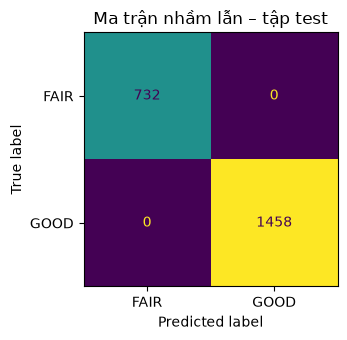

In [5]:
pred_te = clf.predict(Xte)
cls_test = scores(yte, pred_te, 'macro')
cls_val = scores(yva, clf.predict(Xva), 'macro')
cls_lat = latency_ms(clf.predict, Xte)
print(classification_report(yte, pred_te, digits=4, zero_division=0))
print('Độ trễ suy luận 1 mẫu: trung bình {latency_ms_avg:.2f} ms, p95 {latency_ms_p95:.2f} ms'.format(**cls_lat))

fig, ax = plt.subplots(figsize=(4, 3.5))
ConfusionMatrixDisplay(confusion_matrix(yte, pred_te, labels=CLASSES), display_labels=CLASSES).plot(ax=ax, colorbar=False)
ax.set_title('Ma trận nhầm lẫn – tập test'); plt.tight_layout(); plt.show()

### A.3 Kiểm tra: mô hình có thật sự tổng quát hóa không?

Trong dữ liệu demo, nhãn được **tính từ SQI**, và SQI lại được tính từ chính các chỉ số cảm biến này. Ngoài ra mỗi ô chỉ nhận một nghiệm thức nên nhãn gắn chặt với ô. Vì vậy điểm số cao ở A.2 có thể chỉ do mô hình học lại công thức SQI hoặc nhận ra ô.

Hai phép kiểm tra dưới đây **không dùng để nghiệm thu**, chỉ để báo cáo trung thực:

1. **Leave-one-plot-out:** huấn luyện trên 2 ô, kiểm tra trên ô thứ 3 mà mô hình chưa từng thấy.
2. **Dự báo ngày mai:** từ trung bình cảm biến hôm nay, dự đoán nhãn của ngày mai, so với cách đơn giản nhất là "ngày mai giống hôm nay".

In [6]:
rows = []
for plot in sorted(ds_l['plot_code'].unique()):
    tr, te = ds_l[ds_l['plot_code'] != plot], ds_l[ds_l['plot_code'] == plot]
    m = RandomForestClassifier(n_estimators=60, max_depth=8, n_jobs=-1, random_state=SEED).fit(tr[FEATURES], tr['label_code'])
    rows.append({'ô kiểm tra': plot, 'nghiệm thức': te['treatment_code'].iloc[0],
                 'nhãn thật có trong ô': ', '.join(sorted(te['label_code'].unique())),
                 'accuracy': round(accuracy_score(te['label_code'], m.predict(te[FEATURES])), 4)})
lopo = pd.DataFrame(rows)
display(lopo)

,ô kiểm tra,nghiệm thức,nhãn thật có trong ô,accuracy
0,P01,T0,FAIR,0.9832
1,P02,T1,"FAIR, GOOD",0.8221
2,P03,T2,GOOD,0.9186


In [7]:
daily = (readings[readings['quality_status'].isin(['VALID', 'CORRECTED'])]
         .assign(day=lambda d: d['measured_at'].dt.tz_localize(None).dt.normalize())
         .groupby(['plot_code', 'day'])[FEATURES].mean().reset_index())
daily = daily.merge(sqi[['plot_code', 'day', 'health_class']], on=['plot_code', 'day'], how='inner')
daily = daily.sort_values(['plot_code', 'day'])
daily['label_tomorrow'] = daily.groupby('plot_code')['health_class'].shift(-1)
daily = daily.dropna(subset=['label_tomorrow'])

cut = daily['day'].quantile(0.7)                       # 70% số ngày đầu để train
tr, te = daily[daily['day'] <= cut], daily[daily['day'] > cut]
m = RandomForestClassifier(n_estimators=60, max_depth=6, random_state=SEED).fit(tr[FEATURES], tr['label_tomorrow'])
nextday = pd.DataFrame({
    'cách dự báo': ['Ngày mai giống hôm nay (baseline)', 'Random Forest'],
    'accuracy': [accuracy_score(te['label_tomorrow'], te['health_class']), accuracy_score(te['label_tomorrow'], m.predict(te[FEATURES]))],
    'f1_macro': [f1_score(te['label_tomorrow'], te['health_class'], average='macro'),
                 f1_score(te['label_tomorrow'], m.predict(te[FEATURES]), average='macro')],
}).round(4)
print(f'Train: {tr.day.min():%d/%m}–{tr.day.max():%d/%m} ({len(tr)} ngày×ô), Test: {te.day.min():%d/%m}–{te.day.max():%d/%m} ({len(te)} ngày×ô)')
display(nextday)

Train: 01/08–31/08 (93 ngày×ô), Test: 01/09–13/09 (39 ngày×ô)


,cách dự báo,accuracy,f1_macro
0,Ngày mai giống hôm nay (baseline),1.0,1.0
1,Random Forest,1.0,1.0


## B. Phát hiện bất thường cảm biến

**Nhãn thật (ground truth):** bản tin có **giá trị sai thật sự**, tức bị QC gắn cờ loại RANGE (vượt miền vật lý hoặc phi lý).

Cờ "thay đổi đột ngột" (`*_SPIKE`) **không** được dùng làm nhãn. Luật này so sánh với bản tin liền trước, nên nó đánh dấu cả lỗi lẫn **bản tin bình thường ngay sau lỗi**, khi giá trị quay về mức cũ. Bảng bên dưới minh họa điều này. Lần chạy đầu dùng cả cờ SPIKE làm nhãn nên một nửa số "bất thường" thực ra là bản tin bình thường, khiến mọi mô hình đều cho kết quả kém. Cờ `TS_INVALID` cũng bị bỏ qua, vì đó là lỗi đồng hồ chứ không phải lỗi giá trị đo.

**Đặc trưng:** giá trị hiện tại, chênh lệch so với bản tin trước, và độ lệch so với trung vị 8 bản tin gần nhất của cùng cảm biến. Tất cả chỉ dùng dữ liệu **quá khứ**, đúng như gateway có được khi chạy thật.

**Chia tập theo thời gian:** 60% thời gian đầu để train, 20% tiếp theo để validation, 20% cuối để test.

In [8]:
VALUE_COLS = ['ph', 'ec', 'soil_moisture', 'n', 'p', 'k']
RANGE_FLAGS = {'PH_RANGE', 'PH_PLAUSIBLE', 'EC_RANGE', 'MOIST_RANGE', 'TEMP_RANGE', 'N_RANGE', 'P_RANGE', 'K_RANGE'}
SPIKE_FLAGS = {'PH_SPIKE', 'MOIST_SPIKE'}

r = readings.sort_values(['sensor_code', 'measured_at']).reset_index(drop=True)
flags = r['quality_flags'].fillna('').str.split('|').apply(lambda f: {x for x in f if x})
r['anomaly'] = flags.apply(lambda f: bool(f & RANGE_FLAGS)).astype(int)
spike_only = flags.apply(lambda f: bool(f & SPIKE_FLAGS) and not (f & RANGE_FLAGS))
print(f'Bản tin lỗi giá trị (nhãn bất thường): {r.anomaly.sum()}')
print(f'Bản tin chỉ có cờ SPIKE (không tính là bất thường): {spike_only.sum()}')
print('\nVí dụ: lỗi thật và bản tin bình thường ngay sau đó, cả hai đều bị cờ SPIKE:')
ex = [j for i in r.index[r.anomaly == 1][:3] for j in (i, i + 1)]
display(r.loc[ex, ['sensor_code', 'measured_at', 'ph', 'soil_moisture', 'quality_flags', 'anomaly']])

g = r.groupby('sensor_code')
AN_FEATURES = list(VALUE_COLS)
for c in VALUE_COLS:
    r[f'd_{c}'] = g[c].diff().abs()
    r[f'dev_{c}'] = (r[c] - g[c].transform(lambda s: s.shift(1).rolling(8, min_periods=1).median())).abs()
    AN_FEATURES += [f'd_{c}', f'dev_{c}']
r[AN_FEATURES] = r[AN_FEATURES].fillna(0)

t1, t2 = r['measured_at'].quantile([0.6, 0.8])
tr = r[r['measured_at'] <= t1]
va = r[(r['measured_at'] > t1) & (r['measured_at'] <= t2)]
te = r[r['measured_at'] > t2]
print('Tỷ lệ bất thường:', ', '.join(f'{n} {d.anomaly.mean():.2%} ({d.anomaly.sum()}/{len(d)})' for n, d in [('train', tr), ('val', va), ('test', te)]))

Bản tin lỗi giá trị (nhãn bất thường): 124
Bản tin chỉ có cờ SPIKE (không tính là bất thường): 124

Ví dụ: lỗi thật và bản tin bình thường ngay sau đó, cả hai đều bị cờ SPIKE:


,sensor_code,measured_at,ph,soil_moisture,quality_flags,anomaly
211,S01,2026-08-03 06:15:00+07:00,15.31,26.55,PH_RANGE|PH_PLAUSIBLE|PH_SPIKE,1
212,S01,2026-08-03 06:30:00+07:00,4.91,25.53,PH_SPIKE,0
288,S01,2026-08-04 01:30:00+07:00,4.86,119.79,MOIST_RANGE|MOIST_SPIKE,1
289,S01,2026-08-04 01:45:00+07:00,4.94,23.33,MOIST_SPIKE,0
377,S01,2026-08-05 00:15:00+07:00,4.96,119.79,MOIST_RANGE|MOIST_SPIKE,1
378,S01,2026-08-05 00:30:00+07:00,4.95,18.98,MOIST_SPIKE,0


Tỷ lệ bất thường: train 0.98% (74/7562), val 0.95% (24/2520), test 1.03% (26/2520)


### B.1 So sánh các cách phát hiện

Hai cách **không cần nhãn lỗi** khi huấn luyện, chỉ học từ dữ liệu bình thường. Điều này phù hợp với thực địa, nơi hiếm khi có nhãn lỗi:

1. **Robust z-score:** học độ dao động bình thường (MAD) của từng chỉ số. Điểm bất thường = độ lệch lớn nhất so với trung vị 8 bản tin trước, chia cho MAD. Rất nhẹ, chỉ vài phép tính, chạy được cả trên vi điều khiển của Sensor Node.
2. **Isolation Forest:** cây ngẫu nhiên cô lập điểm lạ, dùng toàn bộ 18 đặc trưng.

Ngưỡng cảnh báo của mỗi cách được chọn trên **tập validation**: tìm ngưỡng có F1 cao nhất trong số các ngưỡng đạt precision ≥ 0.90, rồi dịch ngưỡng vào giữa khoảng trống giữa điểm bình thường cao nhất và điểm lỗi thấp nhất. Nếu để ngưỡng sát lỗi nhỏ nhất của tập val, mô hình sẽ bỏ sót những lỗi hơi nhỏ hơn ở dữ liệu mới. Mô hình chính là cách có F1 validation cao hơn.

Thêm một dòng **tham khảo**: Random Forest có giám sát, học trực tiếp từ nhãn. Cách này cần nhãn lỗi nên không chọn làm mô hình chính.

In [9]:
def pick_threshold(y, s):
    p, rc, th = precision_recall_curve(y, s)
    f1s = 2 * p * rc / np.clip(p + rc, 1e-9, None)
    ok = p[:-1] >= THRESHOLDS['precision']
    i = np.argmax(np.where(ok, f1s[:-1], -1)) if ok.any() else np.argmax(f1s[:-1])
    # th[i] nằm sát điểm của lỗi nhỏ nhất trong val. Đặt ngưỡng ở giữa (trung bình nhân) khoảng trống
    # giữa điểm bình thường cao nhất bên dưới và th[i], để không bỏ sót lỗi hơi nhỏ hơn ở dữ liệu mới.
    below = s[(np.asarray(y) == 0) & (s < th[i])]
    return float(np.sqrt(th[i] * below.max())) if len(below) and below.max() > 0 else float(th[i])

# 1. Robust z-score: MAD của độ lệch, ước lượng trên dữ liệu bình thường của tập train
normal_tr = tr[tr['anomaly'] == 0]
MAD = {c: float(1.4826 * np.median(np.abs(normal_tr[f'dev_{c}'] - np.median(normal_tr[f'dev_{c}'])))) or 1e-6
       for c in VALUE_COLS}
z_score = lambda X: np.max(np.column_stack([X[f'dev_{c}'].to_numpy() / MAD[c] for c in VALUE_COLS]), axis=1)

# 2. Isolation Forest
iso = IsolationForest(n_estimators=150, max_samples=256, random_state=SEED).fit(normal_tr[AN_FEATURES])
iso_score = lambda X: -iso.score_samples(X[AN_FEATURES])

detectors = {'Robust z-score (MAD)': z_score, 'Isolation Forest': iso_score}
thresholds, rows = {}, []
for name, sc in detectors.items():
    thresholds[name] = pick_threshold(va['anomaly'], sc(va))
    for split, d in [('val', va), ('test', te)]:
        rows.append({'cách': name, 'tập': split, 'ngưỡng': round(thresholds[name], 4),
                     **{k: round(v, 4) for k, v in scores(d['anomaly'], (sc(d) >= thresholds[name]).astype(int), 'binary').items()}})

rf_an = RandomForestClassifier(n_estimators=60, max_depth=8, class_weight='balanced', n_jobs=-1, random_state=SEED)
rf_an.fit(tr[AN_FEATURES], tr['anomaly'])
rows.append({'cách': 'Random Forest có giám sát (tham khảo)', 'tập': 'test', 'ngưỡng': None,
             **{k: round(v, 4) for k, v in scores(te['anomaly'], rf_an.predict(te[AN_FEATURES]), 'binary').items()}})
cmp_an = pd.DataFrame(rows)
display(cmp_an.set_index(['cách', 'tập']))

val_f1 = cmp_an[cmp_an['tập'] == 'val'].set_index('cách')['f1']
AN_ALGO = val_f1.idxmax()
THRESH = thresholds[AN_ALGO]
print('Chọn:', AN_ALGO)

ngưỡng  accuracy  precision  \
cách                                  tập                                  
Robust z-score (MAD)                  val   31.6773    1.0000        1.0   
                                      test  31.6773    1.0000        1.0   
Isolation Forest                      val    0.6310    0.9909        1.0   
                                      test   0.6310    0.9897        0.0   
Random Forest có giám sát (tham khảo) test      NaN    1.0000        1.0   

                                            recall    f1  
cách                                  tập                 
Robust z-score (MAD)                  val   1.0000  1.00  
                                      test  1.0000  1.00  
Isolation Forest                      val   0.0417  0.08  
                                      test  0.0000  0.00  
Random Forest có giám sát (tham khảo) test  1.0000  1.00

Chọn: Robust z-score (MAD)


### B.2 Đánh giá mô hình được chọn trên tập test

              precision    recall  f1-score   support

 bình thường     1.0000    1.0000    1.0000      2494
  bất thường     1.0000    1.0000    1.0000        26

    accuracy                         1.0000      2520
   macro avg     1.0000    1.0000    1.0000      2520
weighted avg     1.0000    1.0000    1.0000      2520

Độ trễ suy luận 1 mẫu: trung bình 0.255 ms, p95 0.414 ms


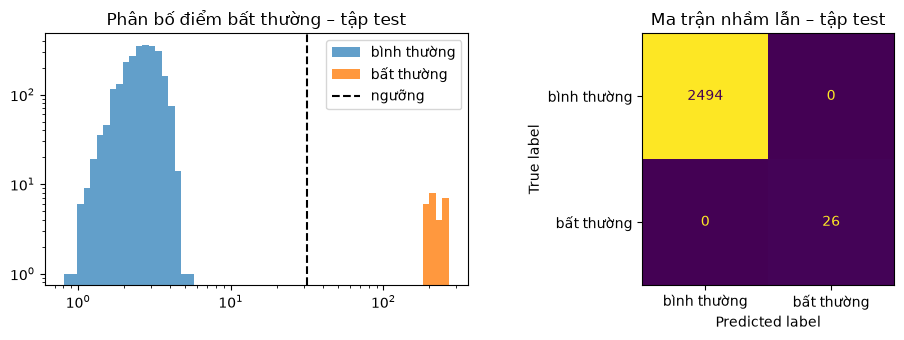

In [10]:
an_score = detectors[AN_ALGO]
an_predict = lambda X: (an_score(X) >= THRESH).astype(int)
an_test = scores(te['anomaly'], an_predict(te), 'binary')
an_val = scores(va['anomaly'], an_predict(va), 'binary')
an_lat = latency_ms(an_predict, te)
print(classification_report(te['anomaly'], an_predict(te), target_names=['bình thường', 'bất thường'], digits=4))
print('Độ trễ suy luận 1 mẫu: trung bình {latency_ms_avg:.3f} ms, p95 {latency_ms_p95:.3f} ms'.format(**an_lat))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
s_te = an_score(te)
log_x = AN_ALGO.startswith('Robust')
bins = np.logspace(np.log10(max(s_te.min(), 1e-3)), np.log10(s_te.max()), 60) if log_x else 60
axes[0].hist(s_te[te['anomaly'] == 0], bins=bins, alpha=.7, label='bình thường')
axes[0].hist(s_te[te['anomaly'] == 1], bins=bins, alpha=.8, label='bất thường')
axes[0].axvline(THRESH, color='k', ls='--', label='ngưỡng'); axes[0].set_yscale('log')
if log_x: axes[0].set_xscale('log')
axes[0].set_title('Phân bố điểm bất thường – tập test'); axes[0].legend()
ConfusionMatrixDisplay(confusion_matrix(te['anomaly'], an_predict(te)), display_labels=['bình thường', 'bất thường']).plot(ax=axes[1], colorbar=False)
axes[1].set_title('Ma trận nhầm lẫn – tập test'); plt.tight_layout(); plt.show()

## C. Đối chiếu tiêu chí nghiệm thu (tập test)

In [11]:
def acceptance(name, m, lat):
    checks = [('Accuracy', m['accuracy'], '≥ 90%', m['accuracy'] >= THRESHOLDS['accuracy']),
              ('Precision', m['precision'], '≥ 90%', m['precision'] >= THRESHOLDS['precision']),
              ('Recall', m['recall'], '≥ 80%', m['recall'] >= THRESHOLDS['recall']),
              ('F1', m['f1'], '≥ 85%', m['f1'] >= THRESHOLDS['f1']),
              ('Suy luận p95 (ms)', lat['latency_ms_p95'], '≤ 2000', lat['latency_ms_p95'] <= THRESHOLDS['latency_ms'])]
    return pd.DataFrame([{'mô hình': name, 'chỉ số': c, 'kết quả': round(v * 100, 2) if c != 'Suy luận p95 (ms)' else round(v, 2),
                          'yêu cầu': req, 'đạt': '✅' if ok else '❌'} for c, v, req, ok in checks])

acc = pd.concat([acceptance('A. SOIL-HEALTH-CLS', cls_test, cls_lat), acceptance('B. SENSOR-ANOMALY', an_test, an_lat)])
display(acc.set_index(['mô hình', 'chỉ số']))
print('Độ trễ đo bằng scikit-learn trên máy tính này; độ trễ thật trên gateway sẽ đo lại ở bước 2 (TFLite).')

kết quả yêu cầu đạt
mô hình            chỉ số                                
A. SOIL-HEALTH-CLS Accuracy            100.00   ≥ 90%   ✅
                   Precision           100.00   ≥ 90%   ✅
                   Recall              100.00   ≥ 80%   ✅
                   F1                  100.00   ≥ 85%   ✅
                   Suy luận p95 (ms)     2.28  ≤ 2000   ✅
B. SENSOR-ANOMALY  Accuracy            100.00   ≥ 90%   ✅
                   Precision           100.00   ≥ 90%   ✅
                   Recall              100.00   ≥ 80%   ✅
                   F1                  100.00   ≥ 85%   ✅
                   Suy luận p95 (ms)     0.41  ≤ 2000   ✅

Độ trễ đo bằng scikit-learn trên máy tính này; độ trễ thật trên gateway sẽ đo lại ở bước 2 (TFLite).


## D. Lưu mô hình và sinh SQL ghi metrics vào database

- `ml/models/*.joblib`: mô hình scikit-learn (bước 2 sẽ chuyển sang TFLite để chạy trên gateway).
- `ml/models/*.json`: mô tả đầu vào/đầu ra, dùng làm `input_schema` khi đăng ký model.
- `ml/output/metrics.json`: toàn bộ metrics.
- `ml/output/register_models.sql`: chạy file này trên database để thay metrics demo bằng metrics thật (version `1.1.0`, framework `SKLEARN`).

In [12]:
VERSION = '1.1.0'
trained_at = pd.Timestamp.now(tz=TZ).isoformat(timespec='seconds')

artifacts = {
    'SOIL-HEALTH-CLS': {
        'file': 'soil_health_cls.joblib', 'model': clf, 'algorithm': best_name,
        'spec': {'task': 'CLASSIFICATION', 'features': FEATURES, 'classes': list(map(str, clf.classes_)),
                 'units': {'ph': 'pH', 'ec': 'dS/m', 'soil_moisture': '%', 'soil_temperature': '°C', 'n': 'mg/kg', 'p': 'mg/kg', 'k': 'mg/kg'}},
        'test': cls_test, 'val': cls_val, 'lat': cls_lat},
    'SENSOR-ANOMALY': {
        'file': 'sensor_anomaly.joblib',
        'model': ({'type': 'robust_zscore', 'mad': MAD, 'threshold': THRESH, 'features': VALUE_COLS, 'history_window': 8}
                  if AN_ALGO.startswith('Robust') else
                  {'type': 'isolation_forest', 'model': iso, 'threshold': THRESH, 'features': AN_FEATURES, 'history_window': 8}),
        'algorithm': AN_ALGO,
        'spec': {'task': 'ANOMALY_DETECTION', 'algorithm': AN_ALGO, 'threshold': THRESH, 'history_window': 8,
                 **({'features': VALUE_COLS, 'mad': MAD,
                     'formula': 'score = max_c |x_c - median(x_c[t-8..t-1])| / mad_c ; bất thường nếu score >= threshold'}
                    if AN_ALGO.startswith('Robust') else
                    {'features': AN_FEATURES,
                     'note': 'd_* = |x_t - x_(t-1)|, dev_* = |x_t - median(x_(t-8..t-1))| của cùng cảm biến'})},
        'test': an_test, 'val': an_val, 'lat': an_lat},
}

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

q = lambda s: "'" + str(s).replace("'", "''") + "'"
sql = [f'-- Sinh tự động bởi ml/01_train_models.ipynb lúc {trained_at}. Chạy lại an toàn (upsert).', 'BEGIN;']
metrics_out = {'version': VERSION, 'trained_at': trained_at, 'dataset_version_no': int(ds.version_no.iloc[0]), 'models': {}}

for code_, a in artifacts.items():
    path = MODEL_DIR / a['file']
    joblib.dump(a['model'], path, compress=3)
    (MODEL_DIR / a['file'].replace('.joblib', '.json')).write_text(json.dumps(a['spec'], ensure_ascii=False, indent=2), encoding='utf-8')
    digest, size_kb = sha256(path), round(path.stat().st_size / 1024, 2)
    metrics_out['models'][code_] = {'algorithm': a['algorithm'], 'artifact': f'ml/models/{a["file"]}', 'sha256': digest,
                                    'size_kb': size_kb, 'test': a['test'], 'val': a['val'], **a['lat']}
    sql.append(f'''
INSERT INTO ml.model_versions (model_id, version, dataset_version_id, framework, quantization, artifact_uri,
                               artifact_sha256, size_kb, input_schema, hyperparameters, target_hardware, status, trained_at)
SELECT m.model_id, {q(VERSION)},
       (SELECT dataset_version_id FROM dataset.dataset_versions WHERE status = 'FROZEN' ORDER BY frozen_at DESC LIMIT 1),
       'SKLEARN', 'FP32', {q('ml/models/' + a['file'])}, {q(digest)}, {size_kb},
       {q(json.dumps(a['spec'], ensure_ascii=False))}::jsonb, {q(json.dumps({'algorithm': a['algorithm']}))}::jsonb,
       'Raspberry Pi 5', 'TRAINED', {q(trained_at)}
FROM ml.models m WHERE m.model_code = {q(code_)}
ON CONFLICT (model_id, version) DO UPDATE
   SET artifact_sha256 = EXCLUDED.artifact_sha256, size_kb = EXCLUDED.size_kb, input_schema = EXCLUDED.input_schema,
       hyperparameters = EXCLUDED.hyperparameters, trained_at = EXCLUDED.trained_at, status = 'TRAINED';''')
    for split, vals in [('TEST', {**a['test'], 'latency_ms_avg': a['lat']['latency_ms_avg'], 'latency_ms_p95': a['lat']['latency_ms_p95']}),
                        ('VAL', a['val'])]:
        for k, v in vals.items():
            sql.append(f'''INSERT INTO ml.model_metrics (model_version_id, dataset_version_id, split, environment, metric_name, metric_value)
SELECT mv.model_version_id, mv.dataset_version_id, {q(split)}, 'OFFLINE', {q(k.upper())}, {round(float(v), 6)}
FROM ml.model_versions mv JOIN ml.models m USING (model_id)
WHERE m.model_code = {q(code_)} AND mv.version = {q(VERSION)}
ON CONFLICT (model_version_id, split, environment, metric_name) DO UPDATE SET metric_value = EXCLUDED.metric_value, evaluated_at = now();''')

sql.append('COMMIT;')
(OUT_DIR / 'register_models.sql').write_text('\n'.join(sql) + '\n', encoding='utf-8')
(OUT_DIR / 'metrics.json').write_text(json.dumps(metrics_out, ensure_ascii=False, indent=2), encoding='utf-8')

for c, m in metrics_out['models'].items():
    print(f"{c:16} {m['algorithm']:32} {m['size_kb']:>8} KB  sha256 {m['sha256'][:16]}…")
print('Đã ghi', OUT_DIR / 'register_models.sql')

SOIL-HEALTH-CLS  Logistic Regression                  1.14 KB  sha256 eaedffc4e6bb3463…
SENSOR-ANOMALY   Robust z-score (MAD)                  0.2 KB  sha256 1156476baeedc6d5…
Đã ghi C:\Users\admin\OneDrive\Documents\phát triển ứng dụng nâng cao\edge_aiot_biochar_db\ml\output\register_models.sql


## Kết luận

**Kết quả trên tập test:** cả hai mô hình đạt toàn bộ tiêu chí nghiệm thu. Tuy nhiên, điểm 100% ở đây phản ánh **dữ liệu demo quá dễ**, không phải mô hình xuất sắc. Khi báo cáo cần nói rõ các điểm sau:

1. **Phân loại sức khỏe đất.** Mô hình được chọn là Logistic Regression, chỉ khoảng 1 KB.
   - Mô hình đạt 100% vì nhãn được tính từ SQI, mà SQI lại tính từ chính các chỉ số đầu vào. Trong dữ liệu demo, hai lớp FAIR/GOOD lại tách nhau rất rõ, và không có mẫu nào thuộc lớp VERY_GOOD hay POOR.
   - Phép thử leave-one-plot-out (A.3) cho accuracy thấp hơn, đặc biệt ở ô P02 là ô có cả hai nhãn. Đây là con số sát với khả năng thật hơn.
   - Dự báo nhãn ngày mai chưa đánh giá được: trong giai đoạn test không có ngày nào đổi nhãn, nên cách đơn giản nhất ("ngày mai giống hôm nay") cũng đạt 100%.
   - Khi có dữ liệu thật, cần dùng nhãn từ phòng thí nghiệm hoặc chuyên gia (TV3/TV4), và có đủ 4 mức sức khỏe đất.
2. **Phát hiện bất thường.** Mô hình được chọn là Robust z-score, chỉ khoảng 0,2 KB và mất chưa tới 1 ms mỗi mẫu.
   - Lỗi trong dữ liệu demo là các giá trị vô lý rõ ràng (độ ẩm khoảng 120%, pH khoảng 15), nên tách được hoàn toàn.
   - Isolation Forest thất bại vì 18 đặc trưng, phần lớn là nhiễu bình thường của N/P/K, làm loãng tín hiệu. Đây là bài học khi chọn mô hình cho thiết bị biên: mô hình đơn giản, đúng bản chất dữ liệu có thể tốt hơn mô hình phức tạp.
   - Dữ liệu thật sẽ có lỗi khó hơn, như cảm biến trôi dần hay kẹt giá trị. Khi đó cần đánh giá lại, và có thể cần thêm đặc trưng theo thời gian dài hơn.
3. **Phát hiện khi làm dữ liệu.** Luật QC "thay đổi đột ngột" đánh dấu cả bản tin bình thường ngay sau lỗi. Nên báo TV4 xem lại luật này, để dashboard chất lượng dữ liệu không đếm lỗi gấp đôi.

**Bước tiếp theo (bước 2):** chuyển mô hình phân loại sang TFLite INT8. Mô hình z-score chỉ là vài phép tính nên có thể viết thẳng trong code gateway. Sau đó đo lại độ trễ trên thiết bị đích và đăng ký version mới với framework `TFLITE`.